# Cyclistic: Model Klasifikasi Pola Perjalanan (Casual vs Member)

**Tujuan.** Melatih model klasifikasi yang belajar membedakan trip *casual* dari trip *member*, lalu memakainya untuk
1. melihat **ciri perjalanan yang paling membedakan** keduanya (feature importance), dan
2. menemukan **trip casual yang polanya mirip member**, diringkas per stasiun x hari x jam x jenis sepeda dan disimpan sebagai `ml_targets.csv` untuk tabel `ml_conversion_targets`.

**Batasan yang harus ditulis di laporan.** Data anonim: satu baris = satu trip, bukan satu orang. Model bekerja di **level trip**.
Skor yang dihasilkan adalah *kemiripan pola dengan member*, **bukan** peluang seseorang menjadi member.

**Alur:** baca data bersih (Silver Parquet) -> fitur -> baseline -> model utama -> evaluasi dan diagnosis overfitting -> feature importance -> skor trip casual -> `ml_targets.csv`.

## 1. Konfigurasi

In [1]:
from pathlib import Path

# ---- Sumber data ----
# Isi dengan folder/file Silver Parquet dari Data Engineer.
PARQUET_PATH = Path("data/silver")            # folder atau file .parquet
# Cadangan bila Parquet belum ada: 12 file CSV bulanan Divvy
CSV_GLOB = "data/raw/*-divvy-tripdata.csv"

# ---- Pengaturan model ----
# Zona waktu: Silver menyimpan started_at dalam UTC, sedangkan data Divvy aslinya waktu lokal Chicago.
SILVER_TZ = "UTC"              # isi None bila started_at sudah waktu lokal (atau bila membaca CSV mentah)
LOCAL_TZ = "America/Chicago"

SAMPLE_FRAC = None        # None = pakai semua data. Isi 0.2 untuk uji coba cepat.
RANDOM_STATE = 42
TEST_SIZE = 0.20
MEMBER_LIKE_THRESHOLD = 0.50   # trip casual dianggap "mirip member" bila skor >= ambang ini
USE_BEHAVIOR_FEATURES = False  # True = tambah durasi/jarak/round-trip (hanya diketahui setelah trip selesai)

# ---- Pengaturan tabel prioritas (PUTUSKAN BERSAMA TIM, catat alasannya di dokumen model) ----
MIN_CASUAL_TRIPS_PER_CELL = 30   # sel dengan trip casual lebih sedikit otomatis "Rendah"
TIER_HIGH_TOP_PCT = 0.20         # 20% sel dengan skor tertinggi -> Prioritas Tinggi
TIER_MID_NEXT_PCT = 0.30         # 30% berikutnya -> Prioritas Sedang

# ---- Penanganan docked_bike ----
# Di data Divvy, docked_bike hanya muncul di trip casual. Bila ikut dilatih, model "menebak" dari kolom ini (kebocoran label).
EXCLUDE_DOCKED_BIKE = True

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

## 2. Impor

In [2]:
import glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_curve)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)

## 3. Membaca data

Kolom Silver Parquet bisa berbeda penamaan dari CSV asli. Sel ini mencocokkan beberapa kemungkinan nama.
Kalau ada kolom wajib yang tidak ditemukan, sel akan berhenti dengan pesan yang jelas: sesuaikan daftar `CANDIDATES` di bawah.

In [3]:
CANDIDATES = {
    "member_casual":    ["member_casual", "user_type"],
    "rideable_type":    ["rideable_type", "bike_type"],
    "started_at":       ["started_at", "start_time", "start_ts"],
    "ended_at":         ["ended_at", "end_time", "end_ts"],          # opsional
    "start_station_id": ["start_station_id"],
    "start_lat":        ["start_lat"],
    "start_lng":        ["start_lng"],
    "is_false_start":   ["is_false_start"],                           # opsional
    "is_outlier_24h":   ["is_outlier_24h"],                           # opsional
}
REQUIRED = ["member_casual", "rideable_type", "started_at", "start_station_id", "start_lat", "start_lng"]


def resolve_columns(available):
    mapping = {}
    for logical, options in CANDIDATES.items():
        found = next((c for c in options if c in available), None)
        if found:
            mapping[logical] = found
    missing = [c for c in REQUIRED if c not in mapping]
    if missing:
        raise KeyError(f"Kolom wajib tidak ditemukan: {missing}. Kolom yang ada: {sorted(available)}")
    return mapping


def load_data():
    if PARQUET_PATH.exists():
        import pyarrow.dataset as ds
        dataset = ds.dataset(str(PARQUET_PATH), format="parquet")
        mapping = resolve_columns(set(dataset.schema.names))
        df = dataset.to_table(columns=list(mapping.values())).to_pandas()
        source = f"Parquet: {PARQUET_PATH}"
    else:
        files = sorted(glob.glob(CSV_GLOB))
        if not files:
            raise FileNotFoundError("Parquet tidak ditemukan dan tidak ada file CSV cadangan. Periksa PARQUET_PATH / CSV_GLOB.")
        header = pd.read_csv(files[0], nrows=0).columns
        mapping = resolve_columns(set(header))
        frames = [pd.read_csv(f, usecols=list(mapping.values()), dtype={mapping["start_station_id"]: "string"}) for f in files]
        df = pd.concat(frames, ignore_index=True)
        source = f"CSV cadangan: {len(files)} file"
    df = df.rename(columns={v: k for k, v in mapping.items()})
    print("Sumber:", source, "| baris:", f"{len(df):,}", "| kolom dipakai:", list(df.columns))
    return df


raw = load_data()
if SAMPLE_FRAC:
    raw = raw.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE).reset_index(drop=True)
    print("Mode sampel:", f"{len(raw):,}", "baris (hasil hanya untuk uji coba)")

Sumber: Parquet: data\silver | baris: 5,722,346 | kolom dipakai: ['member_casual', 'rideable_type', 'started_at', 'ended_at', 'start_station_id', 'start_lat', 'start_lng', 'is_false_start', 'is_outlier_24h']


## 4. Pembersihan dan pembuatan fitur

Aturan pembersihan mengikuti keputusan tim di artefak 3. Bila Silver sudah memuat penanda `is_false_start` / `is_outlier_24h`, penanda itu dipakai.
Bila tidak ada tapi `ended_at` tersedia, aturan yang sama dihitung dari durasi (kurang dari 1 menit atau lebih dari 24 jam).
**Pastikan aturan ini sama dengan yang dipakai Data Engineer di database.**

Fitur dasar hanya memakai informasi yang **sudah diketahui saat trip dimulai** (kapan, di mana, jenis sepeda), karena hasilnya dipakai untuk menentukan *kapan dan di mana* promosi dipasang.

In [4]:
df = raw.copy()
df["started_at"] = pd.to_datetime(df["started_at"])
if SILVER_TZ and PARQUET_PATH.exists():   # CSV mentah sudah waktu lokal, jadi tidak diubah
    df["started_at"] = df["started_at"].dt.tz_localize(SILVER_TZ).dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
n0 = len(df)

# --- penanda data kotor ---
if "ended_at" in df.columns:
    df["ended_at"] = pd.to_datetime(df["ended_at"])
    df["duration_min"] = (df["ended_at"] - df["started_at"]).dt.total_seconds() / 60
else:
    df["duration_min"] = np.nan

drop_mask = pd.Series(False, index=df.index)
if "is_false_start" in df.columns or "is_outlier_24h" in df.columns:
    for c in ("is_false_start", "is_outlier_24h"):
        if c in df.columns:
            drop_mask |= df[c].fillna(False).astype(bool)
    rule = "penanda dari Silver"
elif df["duration_min"].notna().any():
    drop_mask = (df["duration_min"] < 1) | (df["duration_min"] > 24 * 60)
    rule = "durasi < 1 menit atau > 24 jam"
else:
    rule = "tidak ada aturan (tidak ada ended_at maupun penanda)"
df = df.loc[~drop_mask].copy()
print(f"Aturan: {rule} | baris dibuang: {drop_mask.sum():,} dari {n0:,}")

# --- docked_bike ---
print("\nSebaran jenis sepeda per tipe pengguna (cek kebocoran label):")
print(pd.crosstab(df["rideable_type"], df["member_casual"]))
if EXCLUDE_DOCKED_BIKE:
    n_docked = (df["rideable_type"] == "docked_bike").sum()
    df = df[df["rideable_type"] != "docked_bike"].copy()
    print(f"docked_bike dikeluarkan dari pelatihan dan ml_targets: {n_docked:,} baris")

# --- fitur ---
df["start_station_id"] = df["start_station_id"].astype("string").fillna("UNKNOWN")
df["station_unknown"] = (df["start_station_id"] == "UNKNOWN").astype(int)
df["hour_key"] = df["started_at"].dt.hour.astype(int)
df["dow"] = df["started_at"].dt.dayofweek.astype(int)          # 0 = Senin
df["day_name"] = df["started_at"].dt.day_name()                 # 'Monday'..'Sunday'
df["is_weekend"] = (df["dow"] >= 5).astype(int)
df["month"] = df["started_at"].dt.month.astype(int)
df["is_electric"] = (df["rideable_type"] == "electric_bike").astype(int)
for c in ("start_lat", "start_lng"):
    df[c] = df[c].astype(float)
    df[c] = df[c].fillna(df[c].median())

NUM_FEATURES = ["start_lat", "start_lng"]
CAT_FEATURES = ["hour_key", "dow", "month"]
FLAG_FEATURES = ["is_weekend", "is_electric", "station_unknown"]

if USE_BEHAVIOR_FEATURES and df["duration_min"].notna().any():
    df["duration_min"] = df["duration_min"].clip(upper=24 * 60)
    NUM_FEATURES += ["duration_min"]

FEATURES = NUM_FEATURES + CAT_FEATURES + FLAG_FEATURES
y = (df["member_casual"] == "member").astype(int)     # member = 1, casual = 0
X = df[FEATURES].copy()
print("\nFitur:", FEATURES)
print("Proporsi kelas (1 = member):", y.mean().round(3), "| baris akhir:", f"{len(df):,}")

Aturan: penanda dari Silver | baris dibuang: 93,229 dari 5,722,346

Sebaran jenis sepeda per tipe pengguna (cek kebocoran label):
member_casual   casual   member
rideable_type                  
classic_bike   1242030  1963143
docked_bike     300668        0
electric_bike   964851  1158425
docked_bike dikeluarkan dari pelatihan dan ml_targets: 300,668 baris

Fitur: ['start_lat', 'start_lng', 'hour_key', 'dow', 'month', 'is_weekend', 'is_electric', 'station_unknown']
Proporsi kelas (1 = member): 0.586 | baris akhir: 5,328,449


## 5. Pemisahan data latih dan uji
Utama: **acak berstratifikasi** (80/20). Pemisahan berbasis waktu dipakai sebagai uji ketahanan di bagian 7.

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"Latih: {len(X_tr):,} | Uji: {len(X_te):,}")

Latih: 4,262,759 | Uji: 1,065,690


## 6. Baseline dan model utama

In [6]:
def evaluate(name, model, X_train, y_train, X_test, y_test, threshold=0.5):
    p_tr = model.predict_proba(X_train)[:, 1]
    p_te = model.predict_proba(X_test)[:, 1]
    pred = (p_te >= threshold).astype(int)
    return {
        "model": name,
        "auc_latih": roc_auc_score(y_train, p_tr),
        "auc_uji": roc_auc_score(y_test, p_te),
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
    }, p_te

results = []

# 0) Dummy (selalu menebak kelas terbanyak)
dummy = DummyClassifier(strategy="prior").fit(X_tr, y_tr)
r, _ = evaluate("Dummy (kelas terbanyak)", dummy, X_tr, y_tr, X_te, y_te)
results.append(r)

# 1) Logistic Regression (baseline). Dilatih pada sampel agar cepat.
prep = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT_FEATURES),
    ("num", StandardScaler(), NUM_FEATURES),
], remainder="passthrough")
lr = make_pipeline(prep, LogisticRegression(max_iter=300))
lr_idx = X_tr.sample(n=min(1_000_000, len(X_tr)), random_state=RANDOM_STATE).index
lr.fit(X_tr.loc[lr_idx], y_tr.loc[lr_idx])
r, _ = evaluate("Logistic Regression (baseline)", lr, X_tr, y_tr, X_te, y_te)
results.append(r)

# 2) Model utama: Gradient Boosting (HistGradientBoosting)
hgb = HistGradientBoostingClassifier(
    max_iter=300, learning_rate=0.1, max_leaf_nodes=63, min_samples_leaf=100,
    early_stopping=True, validation_fraction=0.1, n_iter_no_change=15, random_state=RANDOM_STATE,
)
hgb.fit(X_tr, y_tr)
r, p_te = evaluate("Gradient Boosting (model utama)", hgb, X_tr, y_tr, X_te, y_te)
results.append(r)
print("Iterasi terpakai:", hgb.n_iter_)

res_df = pd.DataFrame(results).round(4)
res_df

Iterasi terpakai: 300


,model,auc_latih,auc_uji,accuracy,precision,recall,f1
0,Dummy (kelas terbanyak),0.5000,0.5000,0.5858,0.5858,1.0000,0.7388
1,Logistic Regression (baseline),0.6646,0.6641,0.6301,0.6531,0.7863,0.7135
2,Gradient Boosting (model utama),0.7137,0.7113,0.6619,0.6850,0.7831,0.7308


## 7. Evaluasi dan diagnosis overfitting (artefak 6)

- **Selisih AUC latih vs uji** kecil = tidak ada tanda overfitting berat.
- **Uji berbasis waktu:** latih pada bulan-bulan awal, uji pada bulan-bulan akhir. Hasilnya biasanya lebih rendah karena porsi casual berubah mengikuti musim. Itu bukan kesalahan kode, melainkan keterbatasan data satu tahun.

AUC latih = 0.7137 | AUC uji = 0.7113 | selisih = 0.0024

Confusion matrix (data uji):
               Prediksi casual  Prediksi member
Aktual casual           216527           224849
Aktual member           135410           488904

Uji berbasis waktu (latih 75% periode awal, uji 25% periode akhir): AUC = 0.6771


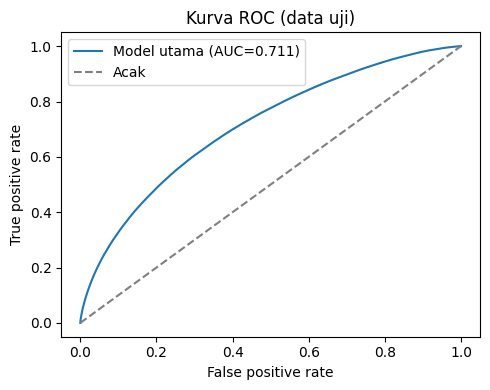

In [7]:
gap = res_df.loc[res_df.model.str.contains("utama"), ["auc_latih", "auc_uji"]].iloc[0]
print(f"AUC latih = {gap.auc_latih:.4f} | AUC uji = {gap.auc_uji:.4f} | selisih = {gap.auc_latih - gap.auc_uji:.4f}")

pred_te = (p_te >= MEMBER_LIKE_THRESHOLD).astype(int)
cm = pd.DataFrame(confusion_matrix(y_te, pred_te), index=["Aktual casual", "Aktual member"], columns=["Prediksi casual", "Prediksi member"])
print("\nConfusion matrix (data uji):")
print(cm)

# Uji ketahanan berbasis waktu
t_mask = df["started_at"] < df["started_at"].min() + (df["started_at"].max() - df["started_at"].min()) * 0.75
hgb_t = HistGradientBoostingClassifier(max_iter=hgb.n_iter_, learning_rate=0.1, max_leaf_nodes=63,
                                       min_samples_leaf=100, random_state=RANDOM_STATE)
hgb_t.fit(X[t_mask], y[t_mask])
auc_time = roc_auc_score(y[~t_mask], hgb_t.predict_proba(X[~t_mask])[:, 1])
print(f"\nUji berbasis waktu (latih 75% periode awal, uji 25% periode akhir): AUC = {auc_time:.4f}")

fpr, tpr, _ = roc_curve(y_te, p_te)
plt.figure(figsize=(5, 4))
plt.plot(fpr, tpr, label=f"Model utama (AUC={gap.auc_uji:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Acak")
plt.xlabel("False positive rate"); plt.ylabel("True positive rate"); plt.title("Kurva ROC (data uji)")
plt.legend(); plt.tight_layout(); plt.savefig(OUTPUT_DIR / "roc_curve.png", dpi=150); plt.show()

## 8. Fitur yang paling membedakan (feature importance)

Memakai *permutation importance* pada sampel data uji: seberapa turun AUC bila satu fitur diacak. Semakin besar penurunannya, semakin berpengaruh fitur itu.

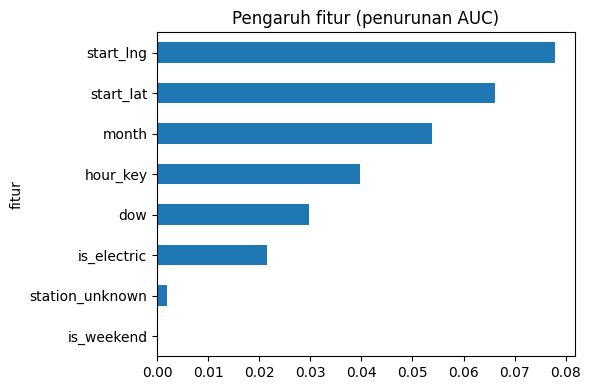

,fitur,penurunan_auc,std
0,start_lng,0.0779,0.0005
1,start_lat,0.0661,0.0006
2,month,0.0538,0.0003
3,hour_key,0.0397,0.0004
4,dow,0.0297,0.0003
5,is_electric,0.0214,0.0004
6,station_unknown,0.0019,0.0000
7,is_weekend,0.0000,0.0000


In [8]:
samp = X_te.sample(n=min(200_000, len(X_te)), random_state=RANDOM_STATE)
perm = permutation_importance(hgb, samp, y_te.loc[samp.index], scoring="roc_auc",
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
imp = (pd.DataFrame({"fitur": FEATURES, "penurunan_auc": perm.importances_mean, "std": perm.importances_std})
       .sort_values("penurunan_auc", ascending=False).reset_index(drop=True))
imp.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)

imp.set_index("fitur")["penurunan_auc"].sort_values().plot.barh(figsize=(6, 4), title="Pengaruh fitur (penurunan AUC)")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "feature_importance.png", dpi=150); plt.show()
imp.round(4)

## 9. Skor trip casual dan pembuatan `ml_targets.csv`

Skor tiap trip dihitung dengan **cross-validation 3 lipatan** (*out-of-fold*): setiap trip diberi skor oleh model yang **tidak pernah melihat trip itu** saat dilatih. Dengan begitu skor tidak terlalu optimistis.

Lalu trip casual diringkas per **stasiun x hari x jam x jenis sepeda**:
- `total_casual_trips` = jumlah trip casual pada sel itu
- `predicted_member_like_trips` = berapa di antaranya berskor >= ambang
- `conversion_propensity_score` = `predicted_member_like_trips / total_casual_trips`. Ini skor *kemiripan pola*, bukan peluang konversi individu
- `priority_tier` = berdasarkan skor dan jumlah trip (aturan di sel konfigurasi)

In [9]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
oof_model = HistGradientBoostingClassifier(max_iter=hgb.n_iter_, learning_rate=0.1, max_leaf_nodes=63,
                                           min_samples_leaf=100, random_state=RANDOM_STATE)
oof = cross_val_predict(oof_model, X, y, cv=cv, method="predict_proba", n_jobs=1)[:, 1]
df["member_like_score"] = oof

casual = df[df["member_casual"] == "casual"].copy()
casual["is_member_like"] = (casual["member_like_score"] >= MEMBER_LIKE_THRESHOLD).astype(int)
print(f"Trip casual: {len(casual):,} | dianggap mirip member (skor >= {MEMBER_LIKE_THRESHOLD}): "
      f"{casual.is_member_like.sum():,} ({casual.is_member_like.mean():.1%})")

targets = (casual.groupby(["start_station_id", "day_name", "hour_key", "rideable_type"], as_index=False)
                 .agg(total_casual_trips=("is_member_like", "size"),
                      predicted_member_like_trips=("is_member_like", "sum")))
targets["conversion_propensity_score"] = (targets["predicted_member_like_trips"] / targets["total_casual_trips"]).round(4)

# --- tingkat prioritas ---
eligible = targets["total_casual_trips"] >= MIN_CASUAL_TRIPS_PER_CELL
rank = targets.loc[eligible, "conversion_propensity_score"].rank(pct=True, ascending=False, method="first")
targets["priority_tier"] = "Rendah"
targets.loc[rank[rank <= TIER_HIGH_TOP_PCT].index, "priority_tier"] = "Prioritas Tinggi"
mid = (rank > TIER_HIGH_TOP_PCT) & (rank <= TIER_HIGH_TOP_PCT + TIER_MID_NEXT_PCT)
targets.loc[rank[mid].index, "priority_tier"] = "Prioritas Sedang"

targets["start_station_id"] = targets["start_station_id"].astype(str)
targets["total_casual_trips"] = targets["total_casual_trips"].astype(int)
targets["predicted_member_like_trips"] = targets["predicted_member_like_trips"].astype(int)
targets["hour_key"] = targets["hour_key"].astype(int)

COLUMNS = ["start_station_id", "day_name", "hour_key", "rideable_type", "total_casual_trips",
           "predicted_member_like_trips", "conversion_propensity_score", "priority_tier"]
targets = targets[COLUMNS]
print("Sebaran tingkat prioritas:")
print(targets["priority_tier"].value_counts())
targets.head()

Trip casual: 2,206,881 | dianggap mirip member (skor >= 0.5): 1,123,509 (50.9%)
Sebaran tingkat prioritas:
priority_tier
Rendah              148531
Prioritas Sedang      4646
Prioritas Tinggi      3097
Name: count, dtype: int64


,start_station_id,day_name,hour_key,rideable_type,total_casual_trips,predicted_member_like_trips,conversion_propensity_score,priority_tier
0,13001,Friday,0,classic_bike,12,1,0.0833,Rendah
1,13001,Friday,0,electric_bike,3,0,0.0000,Rendah
2,13001,Friday,1,classic_bike,7,1,0.1429,Rendah
3,13001,Friday,1,electric_bike,4,0,0.0000,Rendah
4,13001,Friday,2,classic_bike,8,1,0.1250,Rendah


## 10. Validasi format dan simpan
Pemeriksaan otomatis supaya CSV sesuai permintaan Data Engineer sebelum dikirim.

In [10]:
assert list(targets.columns) == COLUMNS, "Urutan/nama kolom tidak sesuai"
assert targets["hour_key"].between(0, 23).all()
assert targets["day_name"].isin(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]).all()
assert targets["rideable_type"].isin(["classic_bike", "electric_bike", "docked_bike"]).all()
assert targets["conversion_propensity_score"].between(0, 1).all()
assert (targets["predicted_member_like_trips"] <= targets["total_casual_trips"]).all()
assert targets["priority_tier"].isin(["Prioritas Tinggi", "Prioritas Sedang", "Rendah"]).all()
assert not targets.duplicated(["start_station_id", "day_name", "hour_key", "rideable_type"]).any()
assert targets.notna().all().all()

targets.to_csv(OUTPUT_DIR / "ml_targets.csv", index=False)

report = {
    "baris_data_dipakai": int(len(df)),
    "aturan_pembersihan": rule,
    "docked_bike_dikeluarkan": bool(EXCLUDE_DOCKED_BIKE),
    "fitur": FEATURES,
    "ambang_member_like": MEMBER_LIKE_THRESHOLD,
    "metrik": res_df.to_dict(orient="records"),
    "auc_uji_berbasis_waktu": float(auc_time),
    "sampel_frac": SAMPLE_FRAC,
}
(OUTPUT_DIR / "model_report.json").write_text(json.dumps(report, indent=2, ensure_ascii=False))
print(f"Tersimpan di {OUTPUT_DIR.resolve()}: ml_targets.csv ({len(targets):,} baris), model_report.json, feature_importance.csv, grafik PNG")

Tersimpan di D:\SISTEM INFORMASI\SEMESTER 5\ANALISIS BIG DATA\project_uas_bigdata\cyclistic-pipeline\output: ml_targets.csv (156,274 baris), model_report.json, feature_importance.csv, grafik PNG


## 11. Bahan untuk laporan (artefak 5 dan 6)

Isi dengan **hasil run tim sendiri**:

| Bagian laporan | Sumber |
|---|---|
| Persoalan pemodelan, label, fitur | Bagian 4 |
| Skema pemisahan latih/uji | Bagian 5 dan 7 |
| Algoritma dan alasan | Baseline Logistic Regression vs Gradient Boosting (bagian 6): isi alasan memilih |
| Ukuran evaluasi dan alasan bisnisnya | Bagian 6 dan 7 (AUC, precision, recall: jelaskan kenapa dipilih) |
| Diagnosis overfitting | Selisih AUC latih-uji, uji berbasis waktu (bagian 7) |
| Fitur pembeda | Bagian 8 |
| Penetapan ambang dan tingkat prioritas | Konfigurasi: tulis alasan angka yang dipilih tim |

**Keterbatasan yang wajib dicantumkan**
- Data anonim: model bekerja di level trip, skor = kemiripan pola, bukan peluang konversi.
- Data hanya 12 bulan (April 2021 sampai Maret 2022), masih dalam periode pandemi, jadi pola musiman hanya satu siklus.
- `docked_bike` dikeluarkan karena hanya dipakai casual (kebocoran label).
- Fitur hanya waktu, lokasi, dan jenis sepeda. Tidak ada informasi demografi atau harga.
- Ambang 0,5 dan batas tingkat prioritas adalah keputusan tim, bukan ketentuan statistik.